# Bonus Hands-on: Image-Text Similarity dengan CLIP

CLIP memetakan **image** dan **text** ke embedding space yang sama.

Pada notebook ini kita akan membandingkan satu image dengan beberapa text candidate seperti:

```text
"a person with blue t-shirt holding a bottle"
"a bottle on a table"
"a red car on the street"
```

Text dengan similarity lebih tinggi dianggap lebih dekat secara semantik dengan image.


## 1. Install Library


In [1]:
!pip -q install -U transformers pillow matplotlib


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 54.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 72.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 83.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.29.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


## 2. Mount Google Drive dan Tentukan Folder Bonus

Notebook ini menggunakan folder `Bonus` pada repo **Language dan Multimodal Reasoning**.

Google Drive di-mount lalu notebook berpindah langsung ke folder tersebut. Tidak ada recursive scan ke seluruh Google Drive.


In [2]:
# Mount Google Drive.
from google.colab import drive

drive.mount(
    "/content/drive"
)

# Import library untuk path.
import os
import sys
from pathlib import Path

# Root project.
VLM_ROOT_DIR = Path(
    "/content/drive/MyDrive/00. Artificial Intelligence (AI)/"
    "Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/"
    "Bagian 4 — Bagaimana Robot Mengambil Keputusan?/"
    "Handson/Language dan Multimodal Reasoning"
)

# Folder Bonus.
PROJECT_DIR = (
    VLM_ROOT_DIR
    / "Bonus"
)

# Cek root project.
if not VLM_ROOT_DIR.exists():
    raise FileNotFoundError(
        "Language dan Multimodal Reasoning directory not found:\n"
        f"{VLM_ROOT_DIR}\n\n"
        "Jika nama folder di Google Drive sedikit berbeda, "
        "ubah hanya nilai VLM_ROOT_DIR pada cell ini."
    )

# Cek folder Bonus.
if not PROJECT_DIR.exists():
    raise FileNotFoundError(
        "Bonus directory not found:\n"
        f"{PROJECT_DIR}"
    )

# Pindah ke folder Bonus.
os.chdir(
    PROJECT_DIR
)

# Tambahkan folder Bonus ke Python import path.
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_DIR),
    )

print(
    "Bonus directory:",
    PROJECT_DIR,
)

print(
    "Current working directory:",
    Path.cwd(),
)

print(
    "Google Drive setup completed."
)


Mounted at /content/drive
Bonus directory: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Language dan Multimodal Reasoning/Bonus
Current working directory: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Language dan Multimodal Reasoning/Bonus
Google Drive setup completed.


## 3. Verifikasi Folder Bonus


In [3]:
# File utama yang diharapkan.
expected_files = [
    "clip_similarity.py",
    "sample_prompts.txt",
    "requirements.txt",
]

print(
    "Bonus files:"
)

for filename in expected_files:
    path = PROJECT_DIR / filename

    print(
        f"- {filename}:",
        "OK" if path.exists() else "MISSING",
    )

# Folder hasil.
RESULTS_DIR = (
    PROJECT_DIR
    / "results"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print(
    "Results directory:",
    RESULTS_DIR,
)


Bonus files:
- clip_similarity.py: OK
- sample_prompts.txt: OK
- requirements.txt: OK
Results directory: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Language dan Multimodal Reasoning/Bonus/results


## 4. Import Library


In [4]:
# Import library.
import gc
from pathlib import Path

import torch
import matplotlib.pyplot as plt

from PIL import Image
from google.colab import files
from transformers import (
    CLIPModel,
    CLIPProcessor,
)

# Folder results sudah dibuat pada Google Drive.
print(
    "Results directory:",
    RESULTS_DIR,
)

# Membersihkan CUDA memory dari model sebelumnya.
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


Results directory: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Language dan Multimodal Reasoning/Bonus/results


## 5. Siapkan Image

Upload image yang ingin dibandingkan dengan text.


In [5]:
# Gunakan person.jpg dari folder Bonus.
image_path = (
    PROJECT_DIR
    / "person.jpg"
)

# Jika person.jpg belum ada, upload image secara manual.
if not image_path.exists():
    print(
        "person.jpg was not found in the Bonus folder."
    )

    uploaded = files.upload()

    uploaded_name = list(
        uploaded.keys()
    )[0]

    image_path = (
        PROJECT_DIR
        / uploaded_name
    )

# Membuka image.
image = Image.open(
    image_path
).convert(
    "RGB"
)

# Menampilkan image.
display(
    image
)

print(
    "Image loaded from:",
    image_path,
)


Output hidden; open in https://colab.research.google.com to view.

## 6. Tentukan Candidate Text

Deskripsi dapat berupa label pendek maupun kalimat yang lebih spesifik.


In [6]:
texts = [
    "a person with blue t-shirt holding a bottle",
    "a person standing near a laptop",
    "a bottle on a table",
    "a person holding a cup",
    "a dog running outside",
    "a red car on the street",
]

for text in texts:
    print(
        "-",
        text
    )


- a person with blue t-shirt holding a bottle
- a person standing near a laptop
- a bottle on a table
- a person holding a cup
- a dog running outside
- a red car on the street


## 7. Load Pretrained CLIP

Kita menggunakan:

```text
openai/clip-vit-base-patch32
```

Tidak ada training tambahan pada hands-on ini.


In [7]:
MODEL_ID = (
    "openai/clip-vit-base-patch32"
)

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else
    "cpu"
)

processor = (
    CLIPProcessor.from_pretrained(
        MODEL_ID
    )
)

model = (
    CLIPModel.from_pretrained(
        MODEL_ID
    ).to(
        device
    )
)

model.eval()

print(
    "Device:",
    device
)


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

...

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Device: cuda


## 8. Process Image dan Text

Processor mengubah image dan text menjadi tensor yang dapat diproses CLIP.


In [8]:
inputs = processor(
    text=texts,
    images=image,
    return_tensors="pt",
    padding=True,
)

inputs = {
    key: value.to(
        device
    )
    for key, value
    in inputs.items()
}


## 9. Membuat Image dan Text Embedding

CLIP memiliki image encoder dan text encoder.

Kedua output berada di embedding space yang sama.


In [9]:
with torch.no_grad():

    outputs = model(
        **inputs
    )

image_embedding = (
    outputs.image_embeds
)

text_embeddings = (
    outputs.text_embeds
)

print(
    "Image embedding shape:",
    image_embedding.shape
)

print(
    "Text embeddings shape:",
    text_embeddings.shape
)


Image embedding shape: torch.Size([1, 512])
Text embeddings shape: torch.Size([6, 512])


## 10. Menghitung Cosine Similarity

Sebelum dibandingkan, embedding dinormalisasi.

Dot product dari normalized embeddings sama dengan cosine similarity.


In [10]:
image_embedding = (
    image_embedding
    /
    image_embedding.norm(
        dim=-1,
        keepdim=True
    )
)

text_embeddings = (
    text_embeddings
    /
    text_embeddings.norm(
        dim=-1,
        keepdim=True
    )
)

similarities = (
    image_embedding
    @ text_embeddings.T
)[0]

order = torch.argsort(
    similarities,
    descending=True
)

for index in order:

    i = int(
        index.item()
    )

    print(
        f"{similarities[i]:.4f}",
        "|",
        texts[i]
    )


0.2699 | a person standing near a laptop
0.2502 | a person with blue t-shirt holding a bottle
0.2452 | a person holding a cup
0.2132 | a bottle on a table
0.1535 | a dog running outside
0.1263 | a red car on the street


## 11. Relative Probability

Softmax pada CLIP logits dapat digunakan untuk melihat perbandingan relatif antar-candidate.

Perlu diingat bahwa ini **bukan calibrated probability absolut**.


In [11]:
relative_probability = (
    outputs.logits_per_image
    .softmax(
        dim=1
    )[0]
)

for index in order:

    i = int(
        index.item()
    )

    print(
        f"{relative_probability[i] * 100:.2f}%",
        "|",
        texts[i]
    )


81.34% | a person standing near a laptop
11.44% | a person with blue t-shirt holding a bottle
6.94% | a person holding a cup
0.28% | a bottle on a table
0.00% | a dog running outside
0.00% | a red car on the street


## 12. Visualisasi Similarity


Chart saved to: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Language dan Multimodal Reasoning/Bonus/results/clip_similarity_result.png
Scores saved to: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Language dan Multimodal Reasoning/Bonus/results/clip_similarity_scores.txt


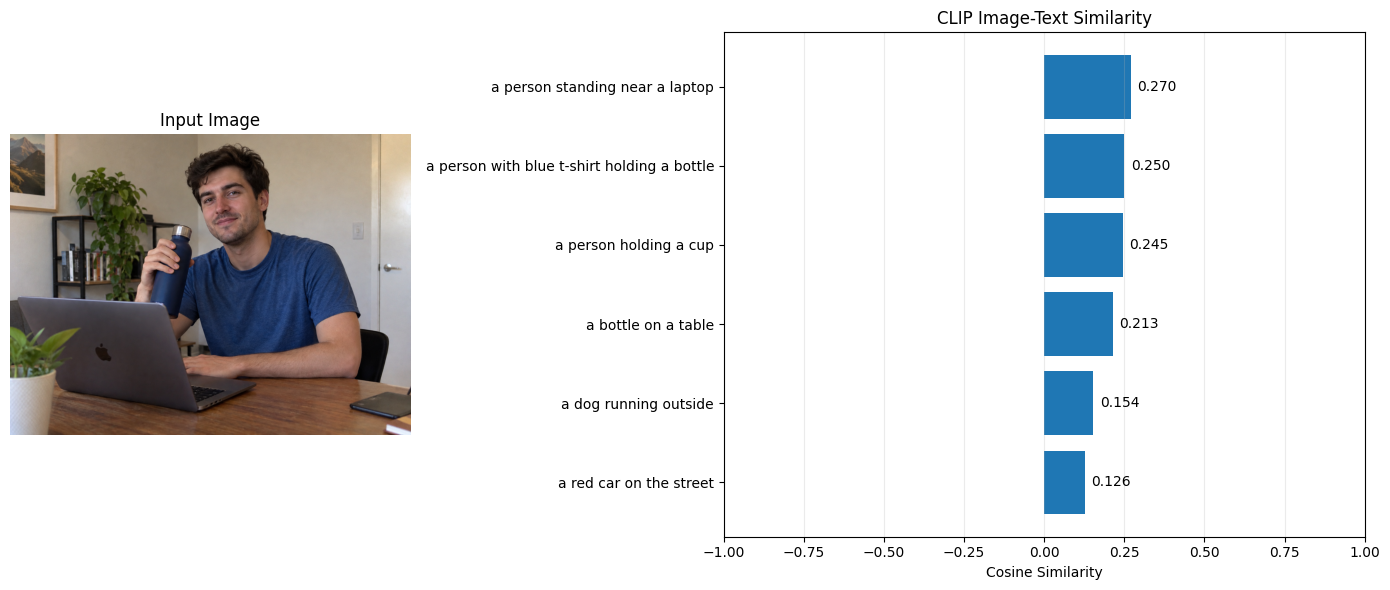

In [12]:
scores = [
    float(
        similarities[i]
    )
    for i
    in range(
        len(texts)
    )
]

order_python = sorted(
    range(
        len(texts)
    ),
    key=lambda i:
        scores[i],
    reverse=True,
)

sorted_texts = [
    texts[i]
    for i in order_python
]

sorted_scores = [
    scores[i]
    for i in order_python
]

# Menyimpan score sebagai text.
result_lines = [
    "Image-Text Similarity",
    "-" * 72,
]

for i in order_python:
    result_lines.append(
        f"{scores[i]: .4f} | "
        f"{float(relative_probability[i]) * 100:6.2f}% | "
        f"{texts[i]}"
    )

scores_path = (
    RESULTS_DIR
    / "clip_similarity_scores.txt"
)

scores_path.write_text(
    "\n".join(result_lines) + "\n",
    encoding="utf-8",
)

# Membuat visualisasi dua panel.
fig, (
    ax_image,
    ax_chart,
) = plt.subplots(
    1,
    2,
    figsize=(14, 6),
    gridspec_kw={
        "width_ratios": [
            1.0,
            1.6,
        ]
    },
)

# Panel kiri menampilkan input image.
ax_image.imshow(
    image
)

ax_image.set_title(
    "Input Image"
)

ax_image.axis(
    "off"
)

# Panel kanan menampilkan similarity ranking.
bars = ax_chart.barh(
    sorted_texts[::-1],
    sorted_scores[::-1],
)

ax_chart.set_xlabel(
    "Cosine Similarity"
)

ax_chart.set_title(
    "CLIP Image-Text Similarity"
)

ax_chart.set_xlim(
    -1.0,
    1.0,
)

ax_chart.grid(
    axis="x",
    alpha=0.25,
)

# Menampilkan score pada bar.
for bar, score in zip(
    bars,
    sorted_scores[::-1],
):
    ax_chart.text(
        score + 0.02,
        bar.get_y()
        + bar.get_height() / 2,
        f"{score:.3f}",
        va="center",
    )

plt.tight_layout()

# Menyimpan hasil visualisasi.
chart_path = (
    RESULTS_DIR
    / "clip_similarity_result.png"
)

plt.savefig(
    chart_path,
    dpi=200,
    bbox_inches="tight",
)

print(
    "Chart saved to:",
    chart_path,
)

print(
    "Scores saved to:",
    scores_path,
)

# Menampilkan gambar.
plt.show()
